# Лабораторна робота №3: Нейронні мережі для табличних даних, зображень і текстів (PyTorch)

**Частина 1:** [NSL-KDD](https://www.kaggle.com/datasets/hassan06/nslkdd), той самий датасет, що в лабораторній №1
**Частина 2:** [Intel Image Classification](https://www.kaggle.com/datasets/puneet6060/intel-image-classification)
**Частина 3:** [20 Newsgroups](http://qwone.com/~jason/20Newsgroups/) (3 класи), той самий датасет, що в лабораторній №2

## 0. Імпорти та функції навчання

In [1]:
import os
import re
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset, Subset

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, f1_score, classification_report

RANDOM_STATE = 42


device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Device:", device)

Device: cpu


Один цикл навчання для всіх частин: `CrossEntropyLoss` + `Adam`, після кожної епохи рахуються loss та accuracy на train і validation
(зберігаються в `history` для learning curves)

In [2]:
def run_epoch(model, loader, criterion, optimizer=None):
    train_mode = optimizer is not None
    model.train(train_mode)
    total_loss, correct, n = 0.0, 0, 0

    with torch.set_grad_enabled(train_mode):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            loss = criterion(logits, yb)

            if train_mode:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * yb.size(0)
            correct += (logits.argmax(dim=1) == yb).sum().item()
            n += yb.size(0)

    return total_loss / n, correct / n


def train_model(model, train_loader, val_loader, epochs, lr=1e-3, verbose=True):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': [], 'epoch_time': []}

    for epoch in range(1, epochs + 1):
        start = time.time()
        tr_loss, tr_acc = run_epoch(model, train_loader, criterion, optimizer)
        va_loss, va_acc = run_epoch(model, val_loader, criterion)

        history['train_loss'].append(tr_loss)
        history['val_loss'].append(va_loss)
        history['train_acc'].append(tr_acc)
        history['val_acc'].append(va_acc)
        history['epoch_time'].append(time.time() - start)

        if verbose:
            print(f"Епоха {epoch:2d}/{epochs}  train_loss={tr_loss:.4f}  val_loss={va_loss:.4f}  "
                  f"train_acc={tr_acc:.4f}  val_acc={va_acc:.4f}  ({history['epoch_time'][-1]:.1f} с)")
    return history


@torch.no_grad()
def predict(model, loader):
    model.eval()
    y_true, y_pred = [], []
    for xb, yb in loader:
        y_pred.append(model(xb.to(device)).argmax(dim=1).cpu())
        y_true.append(yb)
    return torch.cat(y_true).numpy(), torch.cat(y_pred).numpy()


def plot_history(history, title):
    epochs = range(1, len(history['train_loss']) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for ax, metric in zip(axes, ['loss', 'acc']):
        ax.plot(epochs, history[f'train_{metric}'], marker='o', label='train')
        ax.plot(epochs, history[f'val_{metric}'], marker='o', label='validation')
        ax.set_xlabel('Епоха')
        ax.set_title(f'{title}: {metric}')
        ax.legend()
    plt.tight_layout()
    plt.show()


def summary_row(name, history, y_true, y_pred):
    return {
        "model": name,
        "test_accuracy": accuracy_score(y_true, y_pred),
        "test_f1_macro": f1_score(y_true, y_pred, average='macro'),
        "val_acc після 1 епохи": history['val_acc'][0],
        "best val_acc": max(history['val_acc']),
        "епоха best val_acc": int(np.argmax(history['val_acc']) + 1),
        "сер. час епохи (с)": np.mean(history['epoch_time']),
    }

## Частина 1. Повнозв'язна нейронна мережа (MLP) на NSL-KDD

### 1.1. Завантаження та препроцесинг (як у лабораторній №1)

Препроцесинг той самий, що в лабораторній №1: виправлення `.arff`, One-Hot для `protocol_type`/`flag`, Label Encoding для `service`.
Поділ теж офіційний: `KDDTrain+` / `KDDTest+`. Тому результати можна напряму порівняти з лабораторною №1

In [3]:
import kagglehub
from scipy.io import arff

path = kagglehub.dataset_download("hassan06/nslkdd")


def fix_attribute_line(line):
    match = re.match(r"(@attribute\s+'[^']+'\s*)\{(.+)\}\s*$", line.strip(), re.IGNORECASE)
    if not match:
        return line
    head, values_str = match.groups()
    values = [v.strip().strip("'\"") for v in values_str.split(',')]
    return f"{head}{{{','.join(repr(v) for v in values)}}}\n".replace('"', "'")


for src_name, dst_name in {'KDDTrain+.arff': 'KDDTrain_fixed.arff', 'KDDTest+.arff': 'KDDTest_fixed.arff'}.items():
    with open(os.path.join(path, src_name), 'r') as fin, open(dst_name, 'w') as fout:
        for line in fin:
            if line.strip().lower().startswith('@attribute') and '{' in line:
                line = fix_attribute_line(line)
            fout.write(line)

df_train = pd.DataFrame(arff.loadarff('KDDTrain_fixed.arff')[0])
df_test = pd.DataFrame(arff.loadarff('KDDTest_fixed.arff')[0])

object_cols = df_train.select_dtypes(include='object').columns.tolist()
for df_ in (df_train, df_test):
    for col in object_cols:
        df_[col] = df_[col].str.decode('utf-8')

one_hot_cols = ['protocol_type', 'flag']
binary_flag_cols = [c for c in object_cols if c not in one_hot_cols + ['service', 'class']]
le = LabelEncoder().fit(df_train['service'])


def encode(df_):
    df_enc = pd.get_dummies(df_, columns=one_hot_cols)
    df_enc['service_encoded'] = le.transform(df_enc['service'])
    df_enc = df_enc.drop(columns=['service'])
    for col in binary_flag_cols:
        df_enc[col] = df_enc[col].astype(int)
    return df_enc


df_train_enc = encode(df_train)
df_test_enc = encode(df_test)

X_full = df_train_enc.drop(columns=['class'])
y_full = (df_train_enc['class'] == 'anomaly').astype(int).values
X_test_tab = df_test_enc.drop(columns=['class']).reindex(columns=X_full.columns, fill_value=0)
y_test_tab = (df_test_enc['class'] == 'anomaly').astype(int).values

print("Train:", X_full.shape, " Test:", X_test_tab.shape)

Train: (125973, 53)  Test: (22544, 53)


### 1.2. Validation-вибірка, масштабування та DataLoader-и

Для learning curves від `KDDTrain+` відокремлюю 10% як validation, `KDDTest+` залишається для фінальної оцінки.
Нейромережа чутлива до масштабу ознак, тому застосовую `StandardScaler`

In [4]:
X_tr, X_val, y_tr, y_val = train_test_split(
    X_full, y_full, test_size=0.1, stratify=y_full, random_state=RANDOM_STATE
)

scaler = StandardScaler()
X_tr_scaled = scaler.fit_transform(X_tr).astype(np.float32)
X_val_scaled = scaler.transform(X_val).astype(np.float32)
X_test_scaled = scaler.transform(X_test_tab).astype(np.float32)


def to_loader(X, y, shuffle=False):
    ds = TensorDataset(torch.tensor(X), torch.tensor(y, dtype=torch.long))
    return DataLoader(ds, batch_size=256, shuffle=shuffle)


tab_train_loader = to_loader(X_tr_scaled, y_tr, shuffle=True)
tab_val_loader = to_loader(X_val_scaled, y_val)
tab_test_loader = to_loader(X_test_scaled, y_test_tab)

print("Train:", X_tr_scaled.shape, " Val:", X_val_scaled.shape, " Test:", X_test_scaled.shape)

Train: (113375, 53)  Val: (12598, 53)  Test: (22544, 53)


### 1.3. Побудова та навчання MLP

Два приховані шари (128 → 64) з `ReLU` і `Dropout(0.2)`, на виході 2 нейрони (`normal`/`anomaly`)

In [5]:
class MLP(nn.Module):
    def __init__(self, in_features, num_classes=2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_features, 128), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(128, 64), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(64, num_classes),
        )

    def forward(self, x):
        return self.net(x)


torch.manual_seed(RANDOM_STATE)
mlp = MLP(in_features=X_tr_scaled.shape[1])
history_mlp = train_model(mlp, tab_train_loader, tab_val_loader, epochs=30, lr=1e-3)

Епоха  1/30  train_loss=0.0921  val_loss=0.0327  train_acc=0.9711  val_acc=0.9882  (1.4 с)
Епоха  2/30  train_loss=0.0332  val_loss=0.0222  train_acc=0.9886  val_acc=0.9922  (1.5 с)
Епоха  3/30  train_loss=0.0277  val_loss=0.0205  train_acc=0.9905  val_acc=0.9926  (1.4 с)
Епоха  4/30  train_loss=0.0243  val_loss=0.0189  train_acc=0.9915  val_acc=0.9918  (1.4 с)
Епоха  5/30  train_loss=0.0217  val_loss=0.0181  train_acc=0.9923  val_acc=0.9936  (1.4 с)
Епоха  6/30  train_loss=0.0204  val_loss=0.0167  train_acc=0.9931  val_acc=0.9943  (1.5 с)
Епоха  7/30  train_loss=0.0196  val_loss=0.0162  train_acc=0.9936  val_acc=0.9940  (1.3 с)
Епоха  8/30  train_loss=0.0191  val_loss=0.0145  train_acc=0.9934  val_acc=0.9942  (1.4 с)
Епоха  9/30  train_loss=0.0182  val_loss=0.0141  train_acc=0.9935  val_acc=0.9941  (1.4 с)
Епоха 10/30  train_loss=0.0175  val_loss=0.0143  train_acc=0.9941  val_acc=0.9939  (1.5 с)
Епоха 11/30  train_loss=0.0167  val_loss=0.0140  train_acc=0.9943  val_acc=0.9947  (1.4 с)

### 1.4. Learning curves

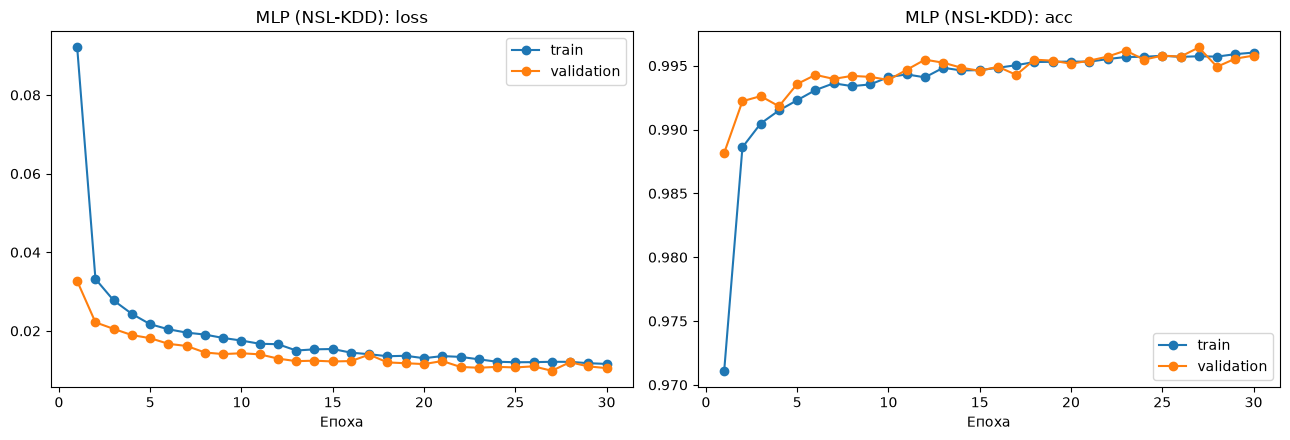

In [6]:
plot_history(history_mlp, 'MLP (NSL-KDD)')

Train_loss і val_loss спадають до кінця навчання (**0.092 → 0.012** та **0.033 → 0.011**), val_acc виходить на плато ≈ **0.995** після ~20 епох.
Val_loss нижчий за train_loss, бо під час навчання діє `Dropout`, а на validation він вимкнений.
**Перенавчання не спостерігається**: val_loss не зростає і розрив між кривими не збільшується

### 1.5. Оцінка на тесті та порівняння з лабораторною №1

In [7]:
y_true_tab, y_pred_tab = predict(mlp, tab_test_loader)
print(classification_report(y_true_tab, y_pred_tab, target_names=['normal', 'anomaly'], digits=3))

lab1_results = pd.DataFrame([
    {"model": "kNN",           "accuracy": 0.807621, "f1_weighted": 0.806619},
    {"model": "SVM",           "accuracy": 0.784555, "f1_weighted": 0.782214},
    {"model": "Random Forest", "accuracy": 0.775816, "f1_weighted": 0.773092},
    {"model": "Decision Tree", "accuracy": 0.773731, "f1_weighted": 0.771000},
    {"model": "AdaBoost",      "accuracy": 0.773643, "f1_weighted": 0.770968},
])
mlp_row = pd.DataFrame([{"model": "MLP (PyTorch)",
                         "accuracy": accuracy_score(y_true_tab, y_pred_tab),
                         "f1_weighted": f1_score(y_true_tab, y_pred_tab, average='weighted')}])
pd.concat([lab1_results, mlp_row], ignore_index=True).sort_values("f1_weighted", ascending=False)

              precision    recall  f1-score   support

      normal      0.678     0.977     0.800      9711
     anomaly      0.973     0.649     0.778     12833

    accuracy                          0.790     22544
   macro avg      0.826     0.813     0.789     22544
weighted avg      0.846     0.790     0.788     22544



,model,accuracy,f1_weighted
0,kNN,0.807621,0.806619
5,MLP (PyTorch),0.789878,0.787816
1,SVM,0.784555,0.782214
2,Random Forest,0.775816,0.773092
3,Decision Tree,0.773731,0.771000
4,AdaBoost,0.773643,0.770968


**Висновок.** На `KDDTest+` MLP показав **accuracy 0.790**. Це друге місце після kNN (0.808), і MLP краще за SVM, Random Forest, Decision Tree та AdaBoost (≈ 0.77–0.78).
Помилки ті самі, що й у класичних моделей: recall `anomaly` лише **0.649**, тобто ≈ 35% атак модель пропускає.
Validation дає ≈ 0.996, test лише 0.790. Ця різниця пояснюється не перенавчанням, а зсувом розподілу: у `KDDTest+` є типи атак, яких немає в `KDDTrain+`.
На табличних даних нейромережа не дає суттєвої переваги над класичними алгоритмами

## Частина 2. Згорткові нейронні мережі (Intel Image Classification)

### 2.1. Опис датасету

In [8]:
from torchvision import datasets, transforms, models

img_path = kagglehub.dataset_download("puneet6060/intel-image-classification")
train_dir = os.path.join(img_path, 'seg_train', 'seg_train')
test_dir = os.path.join(img_path, 'seg_test', 'seg_test')

raw_train = datasets.ImageFolder(train_dir)
raw_test = datasets.ImageFolder(test_dir)
img_classes = raw_train.classes
train_targets = np.array(raw_train.targets)

print("Класи:", img_classes)
print("Розмір зображення:", raw_train[0][0].size)
pd.DataFrame({'train': np.bincount(train_targets), 'test': np.bincount(raw_test.targets)}, index=img_classes)

Класи: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
Розмір зображення: (150, 150)


,train,test
buildings,2191,437
forest,2271,474
glacier,2404,553
mountain,2512,525
sea,2274,510
street,2382,501


У датасеті **17 034** кольорові фото **150×150**, **6 класів** сцен: `buildings`, `forest`, `glacier`, `mountain`, `sea`, `street`.
Train містить **14 034** зображення, test **3 000**. Класи збалансовані (від 2191 до 2512 зображень на клас у train)

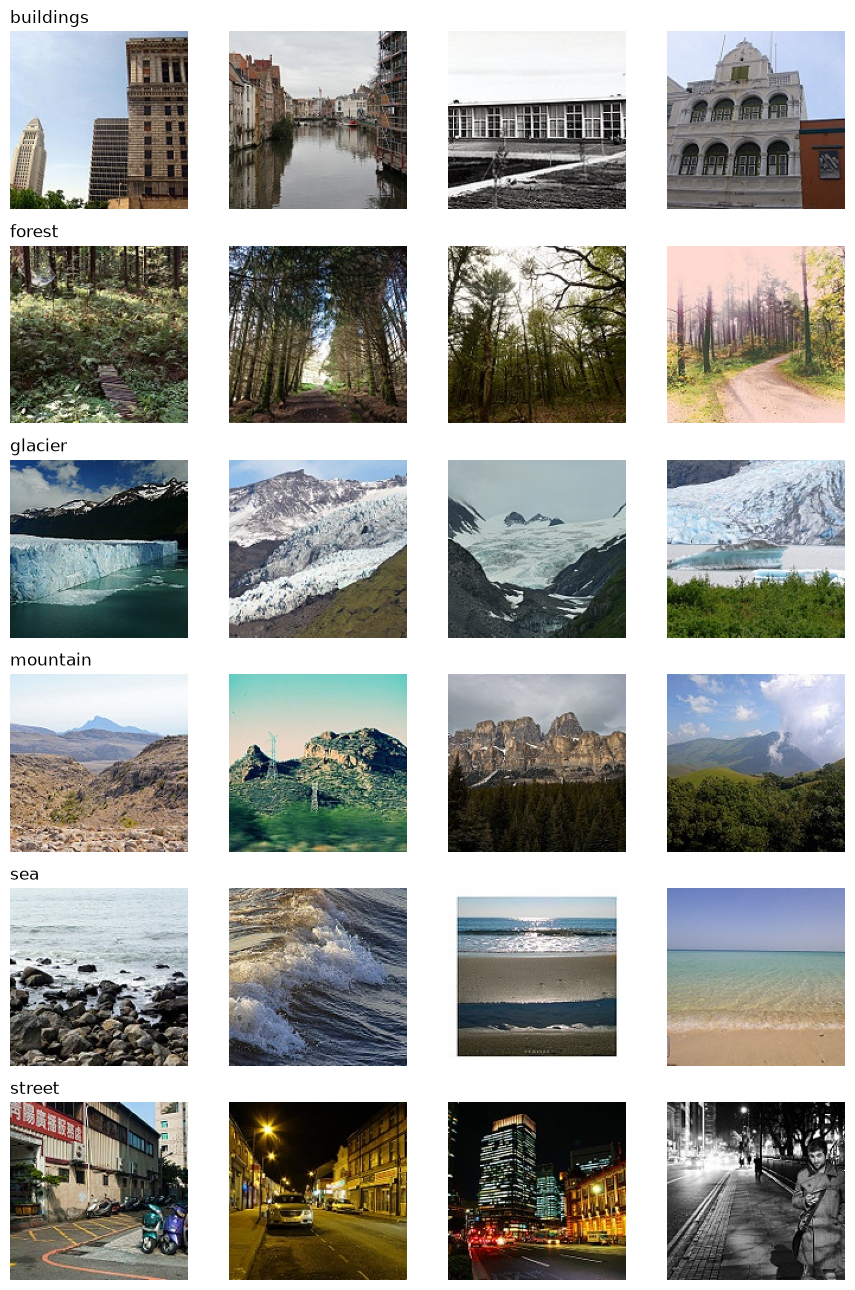

In [9]:
fig, axes = plt.subplots(len(img_classes), 4, figsize=(9, 13))
rng = np.random.RandomState(RANDOM_STATE)
for row, cls_name in enumerate(img_classes):
    for col, i in enumerate(rng.choice(np.where(train_targets == row)[0], 4, replace=False)):
        axes[row, col].imshow(raw_train[i][0])
        axes[row, col].axis('off')
    axes[row, 0].set_title(cls_name, loc='left')
plt.tight_layout()
plt.show()

### 2.2. Підготовка даних

- `seg_train` ділю на train (85%) і validation (15%), `seg_test` використовую як test
- CNN з нуля: зображення **64×64**, нормалізація до [-1, 1]
- ResNet18: зображення **96×96**, нормалізація статистиками ImageNet

In [10]:
tf_scratch = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),
])
tf_pretrained = transforms.Compose([
    transforms.Resize((96, 96)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

img_train_idx, img_val_idx = train_test_split(
    np.arange(len(train_targets)), test_size=0.15, stratify=train_targets, random_state=RANDOM_STATE
)

train_ds_scratch = datasets.ImageFolder(train_dir, transform=tf_scratch)
test_ds_scratch = datasets.ImageFolder(test_dir, transform=tf_scratch)
train_ds_pretrained = datasets.ImageFolder(train_dir, transform=tf_pretrained)
test_ds_pretrained = datasets.ImageFolder(test_dir, transform=tf_pretrained)


def make_img_loaders(full_train_ds, test_ds, train_indices):
    return (DataLoader(Subset(full_train_ds, train_indices), batch_size=64, shuffle=True),
            DataLoader(Subset(full_train_ds, img_val_idx), batch_size=64),
            DataLoader(test_ds, batch_size=64))


scratch_loaders = make_img_loaders(train_ds_scratch, test_ds_scratch, img_train_idx)
pretrained_loaders = make_img_loaders(train_ds_pretrained, test_ds_pretrained, img_train_idx)
print("Train:", len(img_train_idx), " Val:", len(img_val_idx), " Test:", len(test_ds_scratch))

Train: 11928  Val: 2106  Test: 3000


### 2.3. (а) Проста CNN з нуля

Три згорткові блоки `Conv2d(3×3) → ReLU → MaxPool(2×2)` (32 → 64 → 128 фільтрів, розмір 64 → 32 → 16 → 8), після них повнозв'язний шар на 6 класів

In [11]:
class SimpleCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(128 * 8 * 8, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


EPOCHS_SCRATCH = 10
torch.manual_seed(RANDOM_STATE)
cnn = SimpleCNN(len(img_classes))
history_cnn = train_model(cnn, scratch_loaders[0], scratch_loaders[1], epochs=EPOCHS_SCRATCH, lr=1e-3)

Епоха  1/10  train_loss=1.0245  val_loss=0.7739  train_acc=0.6032  val_acc=0.7251  (50.8 с)
Епоха  2/10  train_loss=0.7459  val_loss=0.7596  train_acc=0.7249  val_acc=0.7322  (37.0 с)
Епоха  3/10  train_loss=0.6337  val_loss=0.6198  train_acc=0.7709  val_acc=0.7877  (36.0 с)
Епоха  4/10  train_loss=0.5605  val_loss=0.5667  train_acc=0.8001  val_acc=0.8101  (35.8 с)
Епоха  5/10  train_loss=0.4964  val_loss=0.5815  train_acc=0.8249  val_acc=0.8077  (35.7 с)
Епоха  6/10  train_loss=0.4543  val_loss=0.5789  train_acc=0.8365  val_acc=0.8167  (41.3 с)
Епоха  7/10  train_loss=0.4003  val_loss=0.5948  train_acc=0.8605  val_acc=0.7934  (43.7 с)
Епоха  8/10  train_loss=0.3679  val_loss=0.5476  train_acc=0.8660  val_acc=0.8305  (42.2 с)
Епоха  9/10  train_loss=0.3286  val_loss=0.5588  train_acc=0.8802  val_acc=0.8295  (47.3 с)
Епоха 10/10  train_loss=0.2888  val_loss=0.5520  train_acc=0.8974  val_acc=0.8215  (43.4 с)


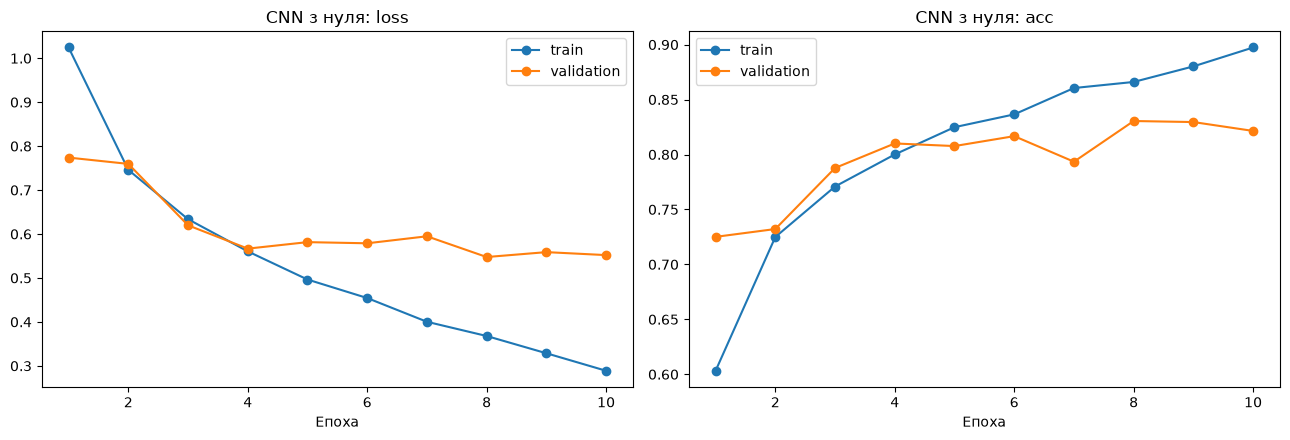

In [12]:
plot_history(history_cnn, 'CNN з нуля')

Train_loss падає весь час (**1.02 → 0.29**), а val_loss знижується лише до 4-ї епохи (≈ 0.57) і далі тримається на ≈ 0.55–0.59.
Val_acc виходить на плато ≈ **0.82**, train_acc тим часом зростає до 0.90. Розрив між кривими збільшується, отже **з 4–5-ї епохи починається перенавчання**

In [13]:
y_true_cnn, y_pred_cnn = predict(cnn, scratch_loaders[2])
print(classification_report(y_true_cnn, y_pred_cnn, target_names=img_classes, digits=3))

              precision    recall  f1-score   support

   buildings      0.859     0.778     0.816       437
      forest      0.962     0.905     0.933       474
     glacier      0.785     0.761     0.773       553
    mountain      0.717     0.821     0.766       525
         sea      0.846     0.776     0.810       510
      street      0.797     0.880     0.837       501

    accuracy                          0.819      3000
   macro avg      0.828     0.820     0.822      3000
weighted avg      0.824     0.819     0.820      3000



### 2.4. (б) Pretrained ResNet18

`ResNet18` попередньо навчена на ImageNet. Її вихідний шар `fc` (512 → 1000) замінюю на `nn.Linear(512, 6)`.
Навчання йде на CPU, тому шари `conv1`…`layer3` заморожую: вони вже вміють виділяти загальні ознаки (краї, текстури).
Донавчаються лише `layer4` і новий `fc`, з малим learning rate `1e-4`

In [14]:
def build_resnet(num_classes):
    model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
    for param in model.parameters():
        param.requires_grad = False
    for param in model.layer4.parameters():
        param.requires_grad = True
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model


EPOCHS_PRETRAINED = 3
torch.manual_seed(RANDOM_STATE)
resnet = build_resnet(len(img_classes))
history_resnet = train_model(resnet, pretrained_loaders[0], pretrained_loaders[1], epochs=EPOCHS_PRETRAINED, lr=1e-4)

Епоха  1/3  train_loss=0.4237  val_loss=0.2709  train_acc=0.8521  val_acc=0.9126  (73.9 с)
Епоха  2/3  train_loss=0.1294  val_loss=0.2734  train_acc=0.9602  val_acc=0.9174  (78.9 с)
Епоха  3/3  train_loss=0.0512  val_loss=0.3108  train_acc=0.9872  val_acc=0.9145  (106.5 с)


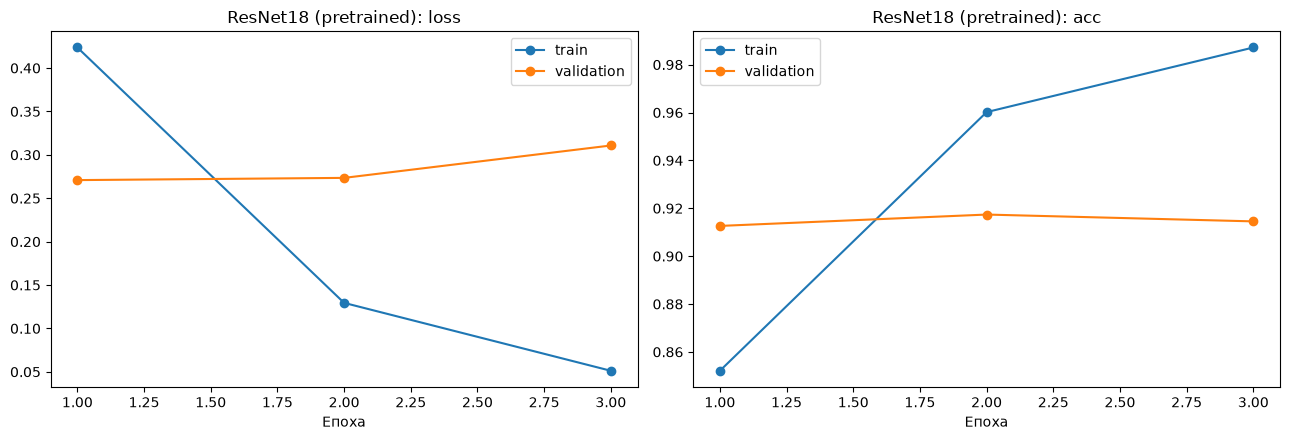

In [15]:
plot_history(history_resnet, 'ResNet18 (pretrained)')

In [16]:
y_true_res, y_pred_res = predict(resnet, pretrained_loaders[2])
print(classification_report(y_true_res, y_pred_res, target_names=img_classes, digits=3))

              precision    recall  f1-score   support

   buildings      0.928     0.908     0.918       437
      forest      0.985     0.987     0.986       474
     glacier      0.857     0.846     0.852       553
    mountain      0.859     0.844     0.851       525
         sea      0.925     0.963     0.943       510
      street      0.923     0.928     0.925       501

    accuracy                          0.911      3000
   macro avg      0.913     0.913     0.913      3000
weighted avg      0.910     0.911     0.910      3000



### 2.5. Порівняння: якість і швидкість збіжності

In [17]:
pd.DataFrame([
    summary_row("CNN з нуля", history_cnn, y_true_cnn, y_pred_cnn),
    summary_row("ResNet18 pretrained", history_resnet, y_true_res, y_pred_res),
]).round(4)

,model,test_accuracy,test_f1_macro,val_acc після 1 епохи,best val_acc,епоха best val_acc,сер. час епохи (с)
0,CNN з нуля,0.8193,0.8224,0.7251,0.8305,8,41.3179
1,ResNet18 pretrained,0.9107,0.9126,0.9126,0.9174,2,86.4219


### 2.6. Вплив обсягу тренувальних даних

Обидві моделі навчаю заново на 10% і 30% train. Validation, test і кількість епох ті самі

In [18]:
data_size_results = [
    {"fraction": 1.0, "model": "CNN з нуля", "test_accuracy": accuracy_score(y_true_cnn, y_pred_cnn)},
    {"fraction": 1.0, "model": "ResNet18", "test_accuracy": accuracy_score(y_true_res, y_pred_res)},
]

for frac in [0.1, 0.3]:
    sub_idx, _ = train_test_split(img_train_idx, train_size=frac,
                                  stratify=train_targets[img_train_idx], random_state=RANDOM_STATE)

    torch.manual_seed(RANDOM_STATE)
    model = SimpleCNN(len(img_classes))
    loaders = make_img_loaders(train_ds_scratch, test_ds_scratch, sub_idx)
    train_model(model, loaders[0], loaders[1], epochs=EPOCHS_SCRATCH, lr=1e-3, verbose=False)
    y_t, y_p = predict(model, loaders[2])
    data_size_results.append({"fraction": frac, "model": "CNN з нуля", "test_accuracy": accuracy_score(y_t, y_p)})

    torch.manual_seed(RANDOM_STATE)
    model = build_resnet(len(img_classes))
    loaders = make_img_loaders(train_ds_pretrained, test_ds_pretrained, sub_idx)
    train_model(model, loaders[0], loaders[1], epochs=EPOCHS_PRETRAINED, lr=1e-4, verbose=False)
    y_t, y_p = predict(model, loaders[2])
    data_size_results.append({"fraction": frac, "model": "ResNet18", "test_accuracy": accuracy_score(y_t, y_p)})

pd.DataFrame(data_size_results).pivot(index="fraction", columns="model", values="test_accuracy").round(4)

model,CNN з нуля,ResNet18
fraction,,
0.1,0.6673,0.8793
0.3,0.7470,0.8963
1.0,0.8193,0.9107


**Висновок.**
- **Якість:** ResNet18 точніша, ніж CNN з нуля: **0.911 проти 0.819** accuracy на test. Обом моделям найважче даються схожі класи `glacier` і `mountain`
- **Збіжність:** ResNet18 досягає val_acc **0.913 вже після 1-ї епохи**, а CNN за 10 епох не перевищила 0.83. Одна епоха ResNet триває довше, бо мережа більша, але для результату їй вистачає 1–2 епох
- **Learning curves:** перенавчаються обидві моделі. У ResNet val_loss мінімальний на 1-й епосі і далі росте, а train_loss падає до 0.05; у CNN val_loss перестає знижуватися після 4-ї епохи
- **Обсяг даних:** якщо скоротити train до 10%, CNN втрачає **15 п.п.** (0.819 → 0.667), а ResNet18 лише **3 п.п.** (0.911 → 0.879). ResNet, навчена на 10% даних, точніша за CNN, навчену на всіх даних, тому що pretrained-ваги вже містять корисні ознаки з ImageNet

## Частина 3. Класифікація текстів (20 Newsgroups)

### 3.1. Завантаження та очищення (як у лабораторній №2)

In [19]:
from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

categories = ['sci.space', 'rec.sport.hockey', 'talk.politics.mideast']
news = fetch_20newsgroups(subset='all', categories=categories, remove=('headers', 'footers', 'quotes'))
df_text = pd.DataFrame({'text': news.data, 'label': [news.target_names[i] for i in news.target]})


def clean_text(text):
    text = re.sub(r'[^a-z\s]', ' ', text.lower())
    return ' '.join(w for w in text.split() if len(w) >= 3 and w not in ENGLISH_STOP_WORDS)


df_text['clean_text'] = df_text['text'].apply(clean_text)
df_text = df_text[df_text['clean_text'] != ''].reset_index(drop=True)

text_classes = sorted(df_text['label'].unique())
df_text['label_id'] = df_text['label'].map({c: i for i, c in enumerate(text_classes)})

txt_train, txt_test, ytxt_train, ytxt_test = train_test_split(
    df_text['clean_text'], df_text['label_id'], test_size=0.25, stratify=df_text['label_id'], random_state=RANDOM_STATE
)
txt_train, txt_val, ytxt_train, ytxt_val = train_test_split(
    txt_train, ytxt_train, test_size=0.15, stratify=ytxt_train, random_state=RANDOM_STATE
)
print("Train:", len(txt_train), " Val:", len(txt_val), " Test:", len(txt_test))

Train: 1813  Val: 320  Test: 711


### 3.2. Токенізація, словник, індекси, padding/truncation

- **Токенізація:** очищений текст розбиваю за пробілами
- **Словник** будую лише на train і беру слова, що трапляються щонайменше 2 рази. `<pad>` має індекс 0, `<unk>` (невідоме слово) має індекс 1
- **Padding/truncation:** довжина `MAX_LEN` дорівнює 90-му перцентилю довжин у train. Довші тексти обрізаються, коротші доповнюються `<pad>`

In [20]:
from collections import Counter

PAD_IDX, UNK_IDX = 0, 1
counter = Counter(tok for text in txt_train for tok in text.split())
itos = ['<pad>', '<unk>'] + [w for w, c in counter.most_common() if c >= 2]
stoi = {w: i for i, w in enumerate(itos)}

MAX_LEN = int(np.percentile(txt_train.str.split().str.len(), 90))


def encode_text(text):
    ids = [stoi.get(tok, UNK_IDX) for tok in text.split()][:MAX_LEN]
    return ids + [PAD_IDX] * (MAX_LEN - len(ids))


def text_loader(texts, labels, shuffle=False):
    X = torch.tensor([encode_text(t) for t in texts], dtype=torch.long)
    y = torch.tensor(labels.values, dtype=torch.long)
    return DataLoader(TensorDataset(X, y), batch_size=64, shuffle=shuffle)


txt_train_loader = text_loader(txt_train, ytxt_train, shuffle=True)
txt_val_loader = text_loader(txt_val, ytxt_val)
txt_test_loader = text_loader(txt_test, ytxt_test)

print("Розмір словника:", len(itos), " MAX_LEN:", MAX_LEN)
print("Приклад:", txt_train.iloc[0].split()[:8], "->", encode_text(txt_train.iloc[0])[:8])

Розмір словника: 14587  MAX_LEN: 236
Приклад: ['birds', 'require', 'constant', 'management', 'survival', 'pointing', 'sensor', 'sun'] -> [8634, 1370, 2699, 1110, 4514, 2430, 7172, 360]


### 3.3. Модель: Embedding → LSTM → Linear

`Embedding` переводить індекси слів у вектори розмірності 100. `LSTM` читає послідовність, а `pack_padded_sequence` не дає їй обробляти `<pad>`-токени.
Останній прихований стан `h_n` подається в `Linear`, який видає 3 класи. Моделі (а) і (б) мають однакову архітектуру, різниця лише в ініціалізації `Embedding`

In [21]:
EMBED_DIM = 100


class TextLSTM(nn.Module):
    def __init__(self, vocab_size, num_classes, pretrained_weights=None):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, EMBED_DIM, padding_idx=PAD_IDX)
        if pretrained_weights is not None:
            self.embedding.weight.data.copy_(torch.tensor(pretrained_weights))
        self.lstm = nn.LSTM(EMBED_DIM, 128, batch_first=True)
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(128, num_classes)

    def forward(self, x):
        lengths = (x != PAD_IDX).sum(dim=1).clamp(min=1).cpu()
        emb = self.dropout(self.embedding(x))
        packed = nn.utils.rnn.pack_padded_sequence(emb, lengths, batch_first=True, enforce_sorted=False)
        _, (h_n, _) = self.lstm(packed)
        return self.fc(self.dropout(h_n[-1]))

### 3.4. (а) Embedding з випадковими вагами

In [22]:
EPOCHS_TEXT = 15
torch.manual_seed(RANDOM_STATE)
lstm_random = TextLSTM(len(itos), len(text_classes))
history_lstm_random = train_model(lstm_random, txt_train_loader, txt_val_loader, epochs=EPOCHS_TEXT, lr=1e-3)

Епоха  1/15  train_loss=1.0914  val_loss=1.0648  train_acc=0.3839  val_acc=0.4688  (19.6 с)
Епоха  2/15  train_loss=1.0470  val_loss=1.0239  train_acc=0.4826  val_acc=0.5062  (20.6 с)
Епоха  3/15  train_loss=0.9284  val_loss=0.8884  train_acc=0.5951  val_acc=0.5938  (21.1 с)
Епоха  4/15  train_loss=0.6881  val_loss=0.7313  train_acc=0.7187  val_acc=0.6937  (18.0 с)
Епоха  5/15  train_loss=0.5334  val_loss=0.5010  train_acc=0.8009  val_acc=0.8125  (18.1 с)
Епоха  6/15  train_loss=0.4796  val_loss=0.5436  train_acc=0.8323  val_acc=0.7750  (17.5 с)
Епоха  7/15  train_loss=0.4622  val_loss=0.6410  train_acc=0.8334  val_acc=0.7719  (17.5 с)
Епоха  8/15  train_loss=0.4263  val_loss=0.4358  train_acc=0.8516  val_acc=0.8406  (17.5 с)
Епоха  9/15  train_loss=0.2837  val_loss=0.5136  train_acc=0.8946  val_acc=0.8281  (17.6 с)
Епоха 10/15  train_loss=0.2624  val_loss=0.4571  train_acc=0.9068  val_acc=0.8531  (17.3 с)
Епоха 11/15  train_loss=0.2340  val_loss=0.4396  train_acc=0.9162  val_acc=0.859

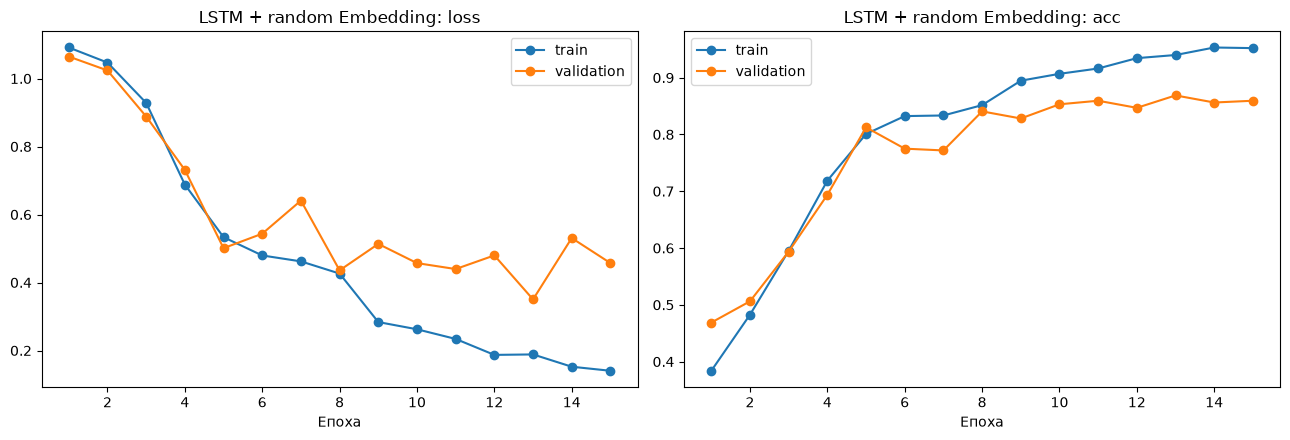

In [23]:
plot_history(history_lstm_random, 'LSTM + random Embedding')

### 3.5. (б) Embedding, ініціалізований GloVe

Беру GloVe 6B розмірністю 100, вона збігається з `EMBED_DIM`. Кожне слово словника отримує свій GloVe-вектор.
Слова, яких у GloVe немає, ініціалізуються випадково, а `<pad>` отримує нульовий вектор. Ваги Embedding під час навчання оновлюються

In [24]:
glove_path = kagglehub.dataset_download("rtatman/glove-global-vectors-for-word-representation")

embedding_matrix = np.random.RandomState(RANDOM_STATE).normal(0, 0.4, (len(itos), EMBED_DIM)).astype(np.float32)
embedding_matrix[PAD_IDX] = 0.0
found = 0
with open(os.path.join(glove_path, 'glove.6B.100d.txt'), encoding='utf8') as f:
    for line in f:
        parts = line.rstrip().split(' ')
        if parts[0] in stoi:
            embedding_matrix[stoi[parts[0]]] = np.asarray(parts[1:], dtype=np.float32)
            found += 1
print(f"Знайдено в GloVe: {found} з {len(itos)} слів ({found / len(itos):.1%})")

torch.manual_seed(RANDOM_STATE)
lstm_glove = TextLSTM(len(itos), len(text_classes), pretrained_weights=embedding_matrix)
history_lstm_glove = train_model(lstm_glove, txt_train_loader, txt_val_loader, epochs=EPOCHS_TEXT, lr=1e-3)

Знайдено в GloVe: 13535 з 14587 слів (92.8%)
Епоха  1/15  train_loss=0.8325  val_loss=0.3513  train_acc=0.6895  val_acc=0.8750  (18.8 с)
Епоха  2/15  train_loss=0.3302  val_loss=0.3703  train_acc=0.8985  val_acc=0.8875  (19.1 с)
Епоха  3/15  train_loss=0.2495  val_loss=0.2181  train_acc=0.9200  val_acc=0.9313  (18.9 с)
Епоха  4/15  train_loss=0.2058  val_loss=0.1970  train_acc=0.9333  val_acc=0.9313  (18.9 с)
Епоха  5/15  train_loss=0.1633  val_loss=0.1974  train_acc=0.9465  val_acc=0.9219  (19.1 с)
Епоха  6/15  train_loss=0.1333  val_loss=0.2037  train_acc=0.9531  val_acc=0.9375  (18.4 с)
Епоха  7/15  train_loss=0.1159  val_loss=0.1694  train_acc=0.9614  val_acc=0.9437  (18.9 с)
Епоха  8/15  train_loss=0.1213  val_loss=0.2074  train_acc=0.9597  val_acc=0.9281  (17.8 с)
Епоха  9/15  train_loss=0.0909  val_loss=0.1814  train_acc=0.9746  val_acc=0.9469  (12.7 с)
Епоха 10/15  train_loss=0.0708  val_loss=0.2050  train_acc=0.9790  val_acc=0.9375  (13.8 с)
Епоха 11/15  train_loss=0.0651  val

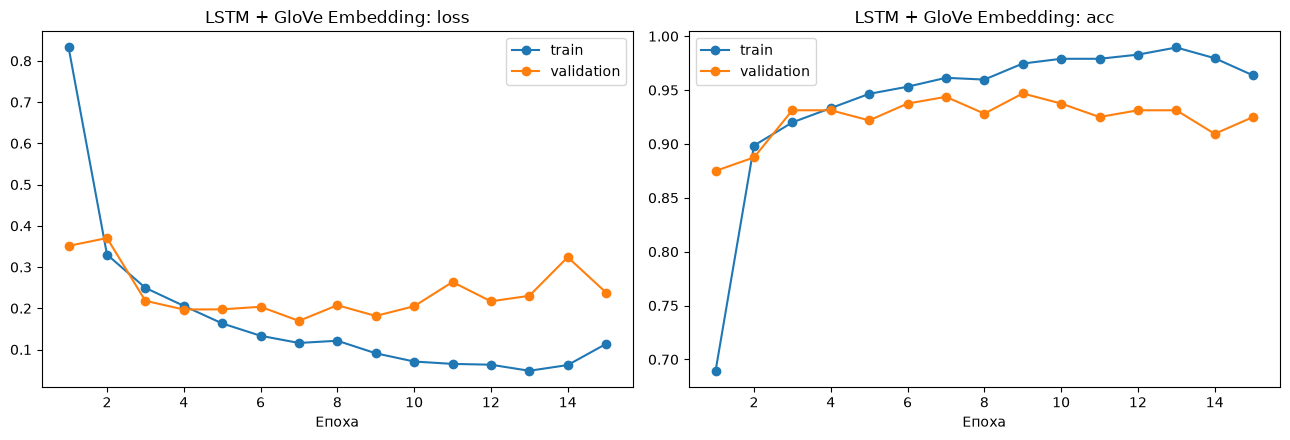

In [25]:
plot_history(history_lstm_glove, 'LSTM + GloVe Embedding')

### 3.6. Порівняння двох підходів

In [26]:
text_preds = {name: predict(model, txt_test_loader)
              for name, model in [('random Embedding', lstm_random), ('GloVe', lstm_glove)]}
for name, (y_t, y_p) in text_preds.items():
    print(f"===== LSTM + {name} =====")
    print(classification_report(y_t, y_p, target_names=text_classes, digits=3))

pd.DataFrame([
    summary_row('LSTM + random Embedding', history_lstm_random, *text_preds['random Embedding']),
    summary_row('LSTM + GloVe', history_lstm_glove, *text_preds['GloVe']),
]).round(4)

===== LSTM + random Embedding =====
                       precision    recall  f1-score   support

     rec.sport.hockey      0.881     0.942     0.911       243
            sci.space      0.877     0.808     0.841       239
talk.politics.mideast      0.861     0.869     0.865       229

             accuracy                          0.873       711
            macro avg      0.873     0.873     0.872       711
         weighted avg      0.873     0.873     0.873       711

===== LSTM + GloVe =====
                       precision    recall  f1-score   support

     rec.sport.hockey      0.870     0.988     0.925       243
            sci.space      0.940     0.925     0.932       239
talk.politics.mideast      0.970     0.847     0.904       229

             accuracy                          0.921       711
            macro avg      0.927     0.920     0.921       711
         weighted avg      0.926     0.921     0.921       711



,model,test_accuracy,test_f1_macro,val_acc після 1 епохи,best val_acc,епоха best val_acc,сер. час епохи (с)
0,LSTM + random Embedding,0.8734,0.8722,0.4688,0.8688,13,18.3902
1,LSTM + GloVe,0.9212,0.9206,0.8750,0.9469,9,16.1032


**Висновок.**
- **Якість:** з GloVe LSTM краща, **accuracy 0.921 проти 0.873** на test
- **Швидкість навчання:** з випадковими ембедінгами модель перші 3 епохи майже не вчиться (val_acc 0.47 → 0.59), а з GloVe має val_acc **0.875 вже після 1-ї епохи**. Час однієї епохи однаковий, бо архітектура та сама
- **Стабільність:** val_loss коливається в обох моделях (у validation лише 320 текстів), але з GloVe він стабільно нижчий: мінімум ≈ 0.17 проти ≈ 0.35
- **Вплив pretrained embeddings:** train малий (1813 текстів), а словник великий (≈ 14.6 тис. слів). З випадкових ваг модель не встигає вивчити значення слів. GloVe покриває ≈ 93% словника і вже кодує семантичну близькість слів, тому модель стартує з кращого представлення